# Simple notebook to test the implementation of the **Generative Modeling by Estimating Gradients of the Data Distribution** paper.

# Code to reproduce the Fig. 1 of the paper.

Reproducing Figure 1 (Left)...
Starting Run: Perturb Data = False
Iter 0: Loss 3.6399
Iter 50: Loss 0.0280
Iter 100: Loss -0.0303
Iter 150: Loss -0.0719
Iter 200: Loss -0.1142
Iter 250: Loss -0.1661
Iter 300: Loss -0.2268
Iter 350: Loss -0.3219
Iter 400: Loss -0.4223
Iter 450: Loss -0.5857
Iter 500: Loss -0.7757
Iter 550: Loss -1.2167
Iter 600: Loss -2.0204
Iter 650: Loss -2.8755
Iter 700: Loss -3.3659
Iter 750: Loss -3.7821
Iter 800: Loss -4.6266
Iter 850: Loss -4.2373
Iter 900: Loss -5.2064
Iter 950: Loss -5.6131
Iter 1000: Loss -2.2892
Iter 1050: Loss -1.9287
Iter 1100: Loss -3.7932
Iter 1150: Loss -2.8592
Iter 1200: Loss -5.8370
Iter 1250: Loss -5.0757
Iter 1300: Loss -5.8072
Iter 1350: Loss -5.4302
Iter 1400: Loss -4.3289
Iter 1450: Loss -3.7819
Iter 1500: Loss -5.4703
Iter 1550: Loss -5.5922
Iter 1600: Loss -4.4443
Iter 1650: Loss -3.0305
Iter 1700: Loss -5.7986
Iter 1750: Loss -6.1227
Iter 1800: Loss -4.2312
Iter 1850: Loss -3.5847
Iter 1900: Loss -1.3098
Iter 1950: Loss -5.7935

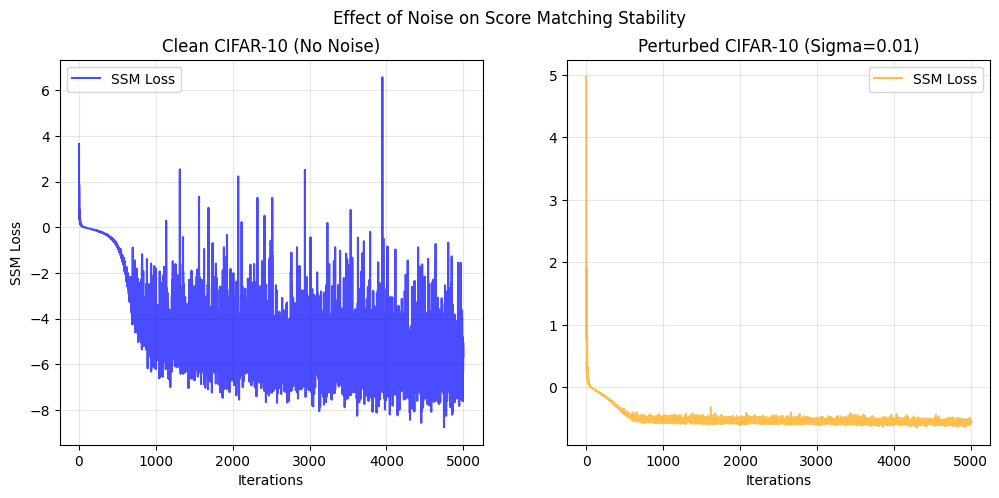

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
LR = 1e-4
ITERATIONS = 5000  # Number of steps to simulate
SIGMA = 0.01

# 1. Define a Simple Score Network
# (A simplified CNN to approximate the ResNet used in the paper for speed)
class SimpleScoreNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ELU(),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ELU(),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.ELU(),
            nn.Conv2d(64, 3, 3, padding=1) # Output matches input shape
        )

    def forward(self, x):
        return self.net(x)

# 2. Sliced Score Matching Loss
def sliced_score_matching_loss(model, samples):
    # Enable gradient calculation for inputs to compute second derivatives
    samples.requires_grad_(True)

    # Random projection vectors (Hutchinson estimator) [cite: 70]
    vectors = torch.randn_like(samples).to(samples.device)
    # Fix: Compute L2 norm across (C, H, W) for each batch item
    norm_val = torch.sqrt(torch.sum(vectors**2, dim=(1,2,3), keepdim=True))
    vectors = vectors / (norm_val + 1e-6) # Add small epsilon for numerical stability

    # Predicted scores
    scores = model(samples)

    # Compute v^T * grad_x s_theta(x) * v
    # We use the vector-Jacobian product trick for efficiency
    v_dot_scores = torch.sum(scores * vectors)
    grad_v_dot_scores = torch.autograd.grad(
        v_dot_scores, samples, create_graph=True
    )[0]

    # Trace term approximation: v^T * Hessian * v
    trace_approx = torch.sum(grad_v_dot_scores * vectors, dim=(1,2,3))

    # Norm term: 1/2 ||s_theta(x)||^2
    norm_term = 0.5 * torch.sum(scores ** 2, dim=(1,2,3))

    # Full loss
    loss = (trace_approx + norm_term).mean()
    return loss

# 3. Data Loading (CIFAR-10)
transform = transforms.Compose([
    transforms.ToTensor(), # Scales to [0, 1]
])
dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform
)
dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True
)

# 4. Training Helper
def run_experiment(perturb_data=False):
    model = SimpleScoreNet().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    losses = []
    data_iter = iter(dataloader)

    print(f"Starting Run: Perturb Data = {perturb_data}")

    for i in range(ITERATIONS):
        try:
            batch, _ = next(data_iter)
        except StopIteration:
            data_iter = iter(dataloader)
            batch, _ = next(data_iter)

        batch = batch.to(DEVICE)

        # [cite: 105, 106] Add Gaussian noise N(0, 0.0001) -> std = 0.01
        if perturb_data:
            noise = torch.randn_like(batch) * SIGMA
            batch = batch + noise

        loss = sliced_score_matching_loss(model, batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if i % 50 == 0:
            print(f"Iter {i}: Loss {loss.item():.4f}")

    return losses

# 5. Execute Experiments
print("Reproducing Figure 1 (Left)...")
loss_clean = run_experiment(perturb_data=False)

print("\nReproducing Figure 1 (Right)...")
loss_perturbed = run_experiment(perturb_data=True)

# 6. Plotting Results
plt.figure(figsize=(12, 5))

# Plot Left: Clean Data
plt.subplot(1, 2, 1)
plt.plot(loss_clean, label='SSM Loss', color='blue', alpha=0.7)
plt.title("Clean CIFAR-10 (No Noise)")
plt.xlabel("Iterations")
plt.ylabel("SSM Loss")
plt.grid(True, alpha=0.3)
plt.legend()

# Plot Right: Perturbed Data
plt.subplot(1, 2, 2)
plt.plot(loss_perturbed, label='SSM Loss', color='orange', alpha=0.7)
plt.title(f"Perturbed CIFAR-10 (Sigma={SIGMA})")
plt.xlabel("Iterations")
plt.grid(True, alpha=0.3)
plt.legend()

plt.suptitle("Effect of Noise on Score Matching Stability")
plt.show()

# Code to reproduce the Fig. 3 of the paper.

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt

MEANS = torch.tensor([[-5.0, -5.0], [0.0, 5.0], [5.0, -5.0]])
WEIGHTS = torch.tensor([0.1, 0.8, 0.1])  # 1/5 and 4/5
SIGMA_DATA = 1.0  # Identity covariance for individual modes

# Figure 3 Setup
SIGMA_START = 10.0
SIGMA_END = 0.1
NUM_L = 10
STEP_LR = 2e-5  # Tuning parameter epsilon
NUM_STEPS_PER_LEVEL = 100

def log_prob_mixture(x, sigma_noise=0.0):
    """
    Computes log p(x) for the mixture of Gaussians.
    If sigma_noise > 0, it computes log q_sigma(x) (perturbed distribution).
    """
    # Total variance = data_variance + noise_variance
    current_var = SIGMA_DATA**2 + sigma_noise**2
    current_sigma = np.sqrt(current_var)

    # x: (B, 2), Means: (2, 2)
    # Expand to (B, 2, 2) to compute distance to both means
    x_expand = x.unsqueeze(1) # (B, 1, 2)
    means_expand = MEANS.unsqueeze(0) # (1, 2, 2)

    # Squared distances: (B, 2 modes)
    dists = torch.sum((x_expand - means_expand)**2, dim=2)

    # Log probabilities of each mode (ignoring constant factors)
    # log N(x; mu, var) = -0.5 * (x-mu)^2 / var - log(sigma)
    log_probs_modes = -0.5 * dists / current_var

    # Add log weights: log(w * p) = log(w) + log(p)
    log_weights = torch.log(WEIGHTS)
    weighted_log_probs = log_probs_modes + log_weights

    # LogSumExp to get log p(x)
    return torch.logsumexp(weighted_log_probs, dim=1)

def exact_score(x, sigma_noise=0.0):
    """
    Computes grad_x log p(x) using autograd for exactness.
    """
    x = x.clone().requires_grad_(True)
    log_p = log_prob_mixture(x, sigma_noise)
    score = torch.autograd.grad(log_p.sum(), x)[0]
    return score

In [17]:
# --- 1. Exact Sampling (Ground Truth) ---
def sample_exact(n_samples=1000):
    # Determine which mode to sample from based on weights
    indices = torch.multinomial(WEIGHTS, n_samples, replacement=True)

    # Sample from N(0, 1) and shift/scale
    samples = torch.randn(n_samples, 2) * SIGMA_DATA

    # Shift by the chosen mean
    chosen_means = MEANS[indices]
    samples = samples + chosen_means
    return samples

# --- 2. Standard Langevin Dynamics (The Failure Case) ---
def sample_langevin_standard(n_samples=1000, n_steps=1000, step_size=1e-2):
    # Initialize from Uniform [-10, 10] roughly covering the space
    x = torch.rand(n_samples, 2) * 20 - 10

    for t in range(n_steps):
        z = torch.randn_like(x)
        # Use exact score of ORIGINAL distribution (sigma_noise=0)
        score = exact_score(x, sigma_noise=0.0)

        # Update
        x = x + 0.5 * step_size * score + np.sqrt(step_size) * z
    return x

# --- 3. Annealed Langevin Dynamics (The Solution) ---
def sample_langevin_annealed(n_samples=1000, epsilon=2e-5, T=100):
    # Initialize
    x = torch.rand(n_samples, 2) * 20 - 10

    # Geometric Schedule [cite: 240]
    sigmas = np.geomspace(SIGMA_START, SIGMA_END, NUM_L)

    for i, sigma in enumerate(sigmas):
        # Step size calculation alpha_i [cite: 219, 234]
        # alpha_i = epsilon * (sigma_i / sigma_L)^2
        # Note: The paper uses relative ratio to sigma_L
        current_step_size = epsilon * (sigma / sigmas[-1])**2

        for t in range(T):
            z = torch.randn_like(x)

            # Use exact score of PERTURBED distribution
            score = exact_score(x, sigma_noise=sigma)

            # Update
            x = x + 0.5 * current_step_size * score + np.sqrt(current_step_size) * z

    return x

Generating Exact Samples...
Running Standard Langevin (this might take a moment)...
Running Annealed Langevin...


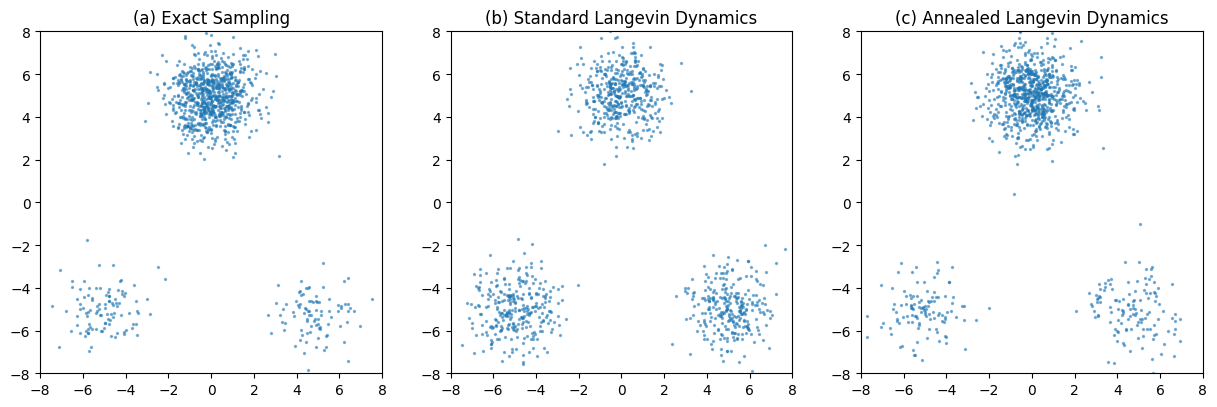

In [18]:
# Generate Samples
print("Generating Exact Samples...")
data_exact = sample_exact(1000)

print("Running Standard Langevin (this might take a moment)...")
# We need a reasonably large number of steps for fair comparison
data_langevin = sample_langevin_standard(n_samples=1000, n_steps=1000, step_size=0.1)

print("Running Annealed Langevin...")
# Using parameters tuned to match the paper's description
data_annealed = sample_langevin_annealed(n_samples=1000, epsilon=2e-3, T=100)

# --- Plotting to Match Figure 3 ---
plt.figure(figsize=(15, 5))

# (a) Exact
plt.subplot(1, 3, 1)
plt.scatter(data_exact[:, 0], data_exact[:, 1], s=2, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8)
plt.title("(a) Exact Sampling")
plt.gca().set_aspect('equal')

# (b) Standard Langevin
plt.subplot(1, 3, 2)
plt.scatter(data_langevin[:, 0], data_langevin[:, 1], s=2, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8)
plt.title("(b) Standard Langevin Dynamics")
plt.gca().set_aspect('equal')

# (c) Annealed Langevin
plt.subplot(1, 3, 3)
plt.scatter(data_annealed[:, 0], data_annealed[:, 1], s=2, alpha=0.5)
plt.xlim(-8, 8); plt.ylim(-8, 8)
plt.title("(c) Annealed Langevin Dynamics")
plt.gca().set_aspect('equal')

plt.show()